# Product image similarity: results

Frozen backbones, a FAISS gallery of 160 known products (1, 3 or 5 references each), and an
"unknown" decision for the 40 products that are never in the gallery. Built on the 200 products
of the bgrm_bm background-removal benchmark. Every number comes from `eval.py`
(`data/results/`). Confidence intervals are 95% intervals from resampling *products*
(1000 resamples), since views of one product are not independent.

Two query sets, always reported separately:
* **synthetic**: 12 views per product made from the main photo (new background, crop,
  rotation, scale, colour jitter). Easy, because the gallery holds the same photo.
* **real**: the product's other ABO listing photos (other angles, packaging, close-ups).
  969 photos. This is the honest test.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
pd.set_option("display.width", 200); pd.set_option("display.precision", 3)
R = Path("data/results"); V = Path("data/views")
S = pd.read_csv(R / "summary.csv"); B = pd.read_csv(R / "breakdown.csv")
L = pd.read_csv(R / "latency.csv"); views = pd.read_csv(V / "views.csv")
NAMES = {"dinov2_s": "DINOv2 ViT-S/14", "dinov2_b": "DINOv2 ViT-B/14", "clip_b32": "CLIP ViT-B/32",
         "siglip_b16": "SigLIP ViT-B/16", "mobilenet_v3": "MobileNetV3-L"}
ORDER = list(NAMES)
def ci(df, m): return df.apply(lambda r: f"{r[m]:.3f} [{r[m+'_lo']:.3f}, {r[m+'_hi']:.3f}]", axis=1)

## 1. Headline: raw images, prototype classifier, 5 references

In [2]:
h = S[(S.arm == "raw") & (S.k == 5) & (S.method == "proto")].copy()
h["backbone"] = pd.Categorical(h.backbone, ORDER)
t = h.sort_values(["queries", "backbone"]).assign(**{
    "top-1": lambda d: ci(d, "top1"), "top-5": lambda d: d.top5.round(3), "mAP": lambda d: d["map"].round(3),
    "AUROC (margin)": lambda d: ci(d, "auroc_margin"), "acc @5% FAR (margin)": lambda d: ci(d, "acc_far5_margin")})
t[["queries", "backbone", "top-1", "top-5", "mAP", "AUROC (margin)", "acc @5% FAR (margin)"]]

,queries,backbone,top-1,top-5,mAP,AUROC (margin),acc @5% FAR (margin)
111,real,dinov2_s,"0.563 [0.511, 0.614]",0.733,0.592,"0.659 [0.590, 0.718]","0.115 [0.080, 0.150]"
69,real,dinov2_b,"0.600 [0.547, 0.654]",0.794,0.629,"0.635 [0.572, 0.692]","0.164 [0.123, 0.204]"
27,real,clip_b32,"0.533 [0.485, 0.585]",0.723,0.501,"0.658 [0.596, 0.709]","0.174 [0.135, 0.217]"
195,real,siglip_b16,"0.770 [0.721, 0.814]",0.890,0.729,"0.783 [0.713, 0.840]","0.274 [0.219, 0.333]"
153,real,mobilenet_v3,"0.477 [0.428, 0.526]",0.644,0.496,"0.650 [0.594, 0.700]","0.191 [0.152, 0.234]"
110,synthetic,dinov2_s,"0.856 [0.835, 0.875]",0.929,0.860,"0.818 [0.770, 0.856]","0.497 [0.454, 0.543]"
68,synthetic,dinov2_b,"0.853 [0.831, 0.873]",0.930,0.857,"0.809 [0.761, 0.851]","0.465 [0.419, 0.514]"
26,synthetic,clip_b32,"0.781 [0.751, 0.810]",0.881,0.706,"0.798 [0.760, 0.831]","0.469 [0.423, 0.512]"
194,synthetic,siglip_b16,"0.924 [0.906, 0.941]",0.968,0.870,"0.891 [0.846, 0.929]","0.607 [0.557, 0.653]"
152,synthetic,mobilenet_v3,"0.864 [0.844, 0.884]",0.938,0.857,"0.826 [0.792, 0.859]","0.540 [0.502, 0.580]"


## 2. Backbone x background-removal arm

`raw` is the image as is; `u2net` and `birefnet-general` composite it onto white with that
model's predicted mask; `oracle` uses the ground-truth matte (synthetic only).

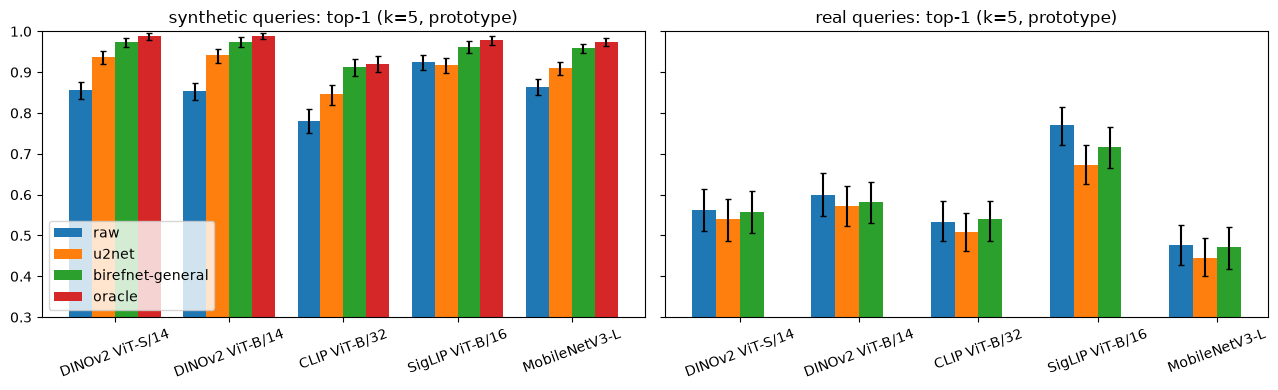

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
arms = ["raw", "u2net", "birefnet-general", "oracle"]
for ax, q in zip(axes, ["synthetic", "real"]):
    d = S[(S.k == 5) & (S.method == "proto") & (S.queries == q)]
    for i, a in enumerate(arms):
        e = d[d.arm == a].set_index("backbone").reindex(ORDER)
        x = np.arange(len(ORDER)) + (i - 1.5) * 0.2
        ax.bar(x, e.top1, 0.2, yerr=[e.top1 - e.top1_lo, e.top1_hi - e.top1], label=a, capsize=2)
    ax.set_xticks(range(len(ORDER)), [NAMES[b] for b in ORDER], rotation=20)
    ax.set_title(f"{q} queries: top-1 (k=5, prototype)"); ax.set_ylim(0.3, 1)
axes[0].legend(); plt.tight_layout()

In [4]:
p = S[(S.k == 5) & (S.method == "proto")].pivot_table(index="backbone", columns=["queries", "arm"], values="top1")
p.reindex(ORDER).round(3)

queries                  real                      synthetic                     
arm          birefnet-general    raw  u2net birefnet-general oracle    raw  u2net
backbone                                                                         
dinov2_s                0.557  0.563  0.539            0.974  0.989  0.856  0.936
dinov2_b                0.582  0.600  0.573            0.975  0.990  0.853  0.942
clip_b32                0.539  0.533  0.508            0.911  0.921  0.781  0.846
siglip_b16              0.717  0.770  0.674            0.962  0.979  0.924  0.917
mobilenet_v3            0.471  0.477  0.445            0.959  0.974  0.864  0.911

## 3. References per product and classifier (k = 1, 3, 5)

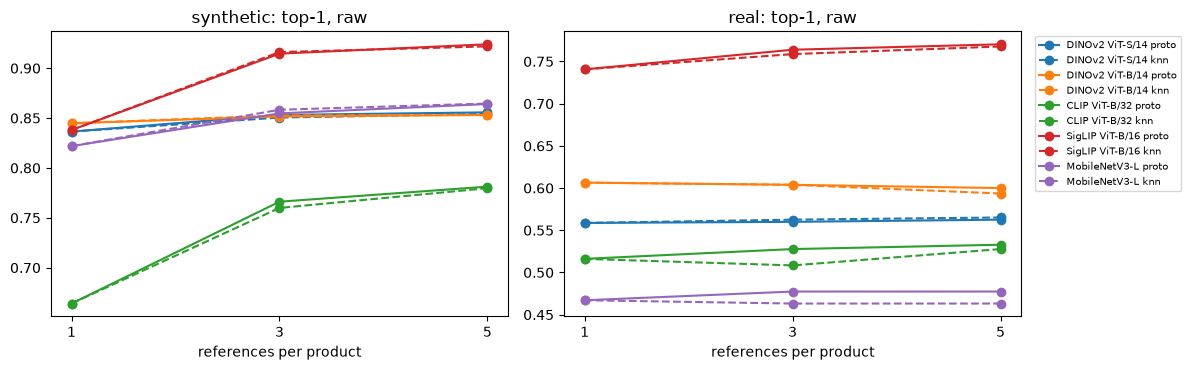

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, q in zip(axes, ["synthetic", "real"]):
    for b in ORDER:
        for m, ls in [("proto", "-"), ("knn", "--")]:
            d = S[(S.arm == "raw") & (S.queries == q) & (S.backbone == b) & (S.method == m)].sort_values("k")
            ax.plot(d.k, d.top1, ls, marker="o", label=f"{NAMES[b]} {m}" if q == "real" else None,
                    color=f"C{ORDER.index(b)}")
    ax.set_xticks([1, 3, 5]); ax.set_xlabel("references per product"); ax.set_title(f"{q}: top-1, raw")
axes[1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout()

References 1-4 are re-placements of the main photo (`ref_0`) on white or plain colours, so
they add little that `ref_0` doesn't already carry: the curves are nearly flat. Real extra
references (other photos) would be needed for k to matter. With k = 1 the prototype and kNN
classifiers are identical by construction.

## 4. Robustness: background and colour jitter (synthetic queries)

In [6]:
b = B[(B.k == 5) & (B.method == "proto") & B.arm.isin(["raw", "birefnet-general"])]
p = b.pivot_table(index=["backbone", "arm"], columns=["bg", "jitter"], values="top1").reindex(ORDER, level=0)
p.round(3)

bg                             clean               texture              
jitter                             0      1      2       0      1      2
backbone     arm                                                        
dinov2_s     birefnet-general  0.991  0.984  0.978   0.972  0.956  0.966
             raw               0.994  1.000  0.991   0.734  0.716  0.700
dinov2_b     birefnet-general  0.994  0.981  0.975   0.975  0.969  0.956
             raw               0.994  0.991  0.978   0.709  0.719  0.728
clip_b32     birefnet-general  0.959  0.950  0.866   0.953  0.928  0.812
             raw               0.950  0.944  0.850   0.700  0.678  0.566
siglip_b16   birefnet-general  0.991  0.981  0.953   0.978  0.953  0.919
             raw               0.994  0.991  0.962   0.884  0.900  0.812
mobilenet_v3 birefnet-general  0.988  0.972  0.950   0.975  0.956  0.912
             raw               0.984  0.981  0.953   0.791  0.756  0.719

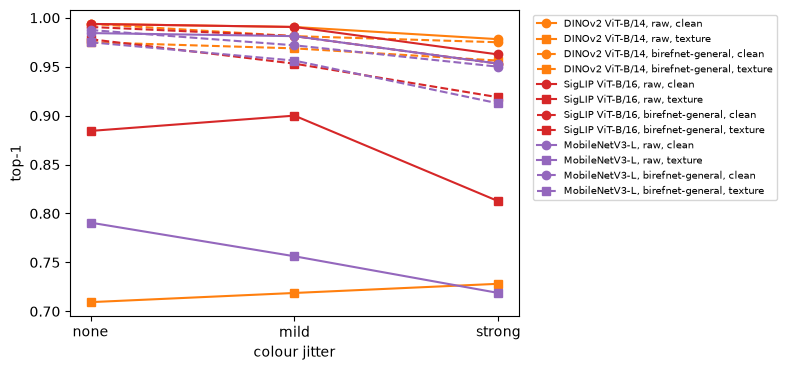

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for b_ in ["dinov2_b", "siglip_b16", "mobilenet_v3"]:
    for a, ls in [("raw", "-"), ("birefnet-general", "--")]:
        for bg, mk in [("clean", "o"), ("texture", "s")]:
            d = B[(B.k == 5) & (B.method == "proto") & (B.backbone == b_) & (B.arm == a) & (B.bg == bg)].sort_values("jitter")
            ax.plot(d.jitter, d.top1, ls, marker=mk, color=f"C{ORDER.index(b_)}",
                    label=f"{NAMES[b_]}, {a}, {bg}")
ax.set_xticks([0, 1, 2], ["none", "mild", "strong"]); ax.set_xlabel("colour jitter"); ax.set_ylabel("top-1")
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout()

## 5. Open-set rejection

Score = top-1 similarity, or the margin between the best and second-best product. The
threshold accepts 5% of unknown queries; it is fitted on one half of the products and applied to
the other half (cross-fitting), so no threshold ever sees its own test queries. `far` is the
false-accept rate actually realised on test.

In [8]:
o = S[(S.k == 5) & (S.method == "proto") & S.arm.isin(["raw", "birefnet-general"])].copy()
o["backbone"] = pd.Categorical(o.backbone, ORDER)
o.sort_values(["queries", "arm", "backbone"])[["queries", "arm", "backbone", "auroc_top1", "auroc_margin",
    "acc_far5_top1", "far_top1", "acc_far5_margin", "far_margin"]].set_index(["queries", "arm", "backbone"])

auroc_top1  auroc_margin  acc_far5_top1  far_top1  acc_far5_margin  far_margin
queries   arm              backbone                                                                                    
real      birefnet-general dinov2_s           0.663         0.654          0.195     0.052            0.121       0.041
                           dinov2_b           0.669         0.618          0.192     0.046            0.137       0.046
                           clip_b32           0.583         0.647          0.174     0.052            0.161       0.057
                           siglip_b16         0.721         0.765          0.308     0.062            0.241       0.067
                           mobilenet_v3       0.656         0.630          0.231     0.046            0.157       0.052
          raw              dinov2_s           0.657         0.659          0.192     0.041            0.115       0.031
                           dinov2_b           0.660         0.635          0.208     0.046            0.164       0.046
                           clip_b32           0.579         0.658          0.152     0.041            0.174       0.108
                           siglip_b16         0.733         0.783          0.330     0.062            0.274       0.072
                           mobilenet_v3       0.642         0.650          0.240     0.052            0.191       0.052
synthetic birefnet-general dinov2_s           0.943         0.902          0.794     0.073            0.577       0.042
                           dinov2_b           0.931         0.899          0.749     0.052            0.471       0.040
                           clip_b32           0.850         0.852          0.540     0.052            0.526       0.050
                           siglip_b16         0.935         0.922          0.817     0.054            0.710       0.081
                           mobilenet_v3       0.938         0.912          0.819     0.052            0.703       0.067
          raw              dinov2_s           0.750         0.818          0.484     0.050            0.497       0.050
                           dinov2_b           0.744         0.809          0.474     0.054            0.465       0.052
                           clip_b32           0.723         0.798          0.350     0.046            0.469       0.042
                           siglip_b16         0.855         0.891          0.608     0.052            0.607       0.077
                           mobilenet_v3       0.756         0.826          0.498     0.054            0.540       0.048

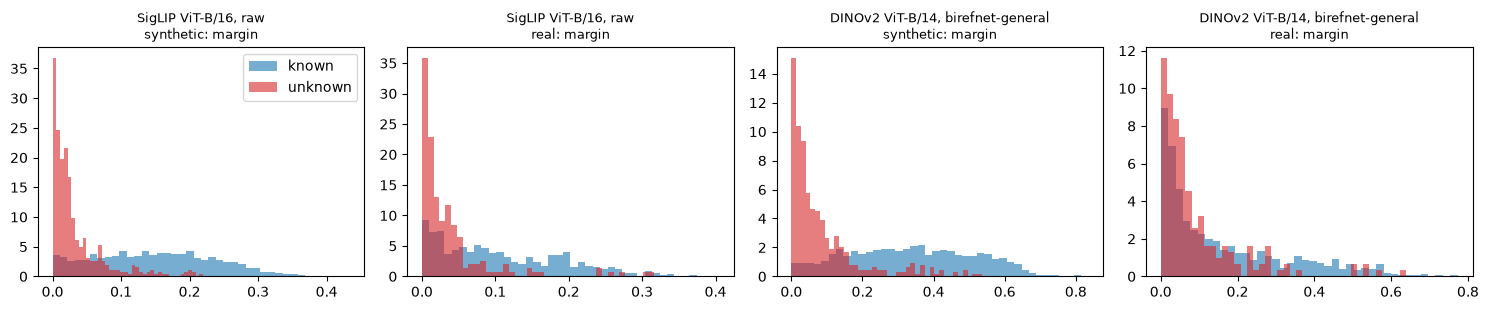

In [9]:
pq = pd.read_csv(R / "per_query.csv.gz")
sel = lambda b, a: pq[(pq.backbone == b) & (pq.arm == a) & (pq.k == 5) & (pq.method == "proto")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for i, (b_, a) in enumerate([("siglip_b16", "raw"), ("dinov2_b", "birefnet-general")]):
    d = sel(b_, a)
    for j, kind in enumerate(["query", "real"]):
        ax = axes[2 * i + j]; e = d[d.kind == kind]
        for split, c in [("known", "C0"), ("unknown", "C3")]:
            ax.hist(e[e.split == split].margin, bins=40, alpha=.6, density=True, color=c, label=split)
        ax.set_title(f"{NAMES[b_]}, {a}\n{'synthetic' if kind == 'query' else 'real'}: margin", fontsize=9)
axes[0].legend(); plt.tight_layout()

## 6. Adding a product needs no retraining

Take a product the gallery has never seen, show it is rejected, then add its references with
`Gallery.add` and query again. Nothing is fitted; the new vectors are searchable at once.

In [10]:
from index import Gallery, prototype_classify
from openset import cross_fit
emb = np.load("data/emb/siglip_b16/raw.npy")
known = views.split.eq("known") & views.kind.eq("ref")
g = Gallery(emb.shape[1]).add(emb[known], views["product"][known])
new = views[views.split.eq("unknown")]["product"].iloc[0]
qm = (views["product"] == new) & views.kind.isin(["query", "real"])
th = sel("siglip_b16", "raw").query("kind == 'query'")
_, t = cross_fit(th.margin.to_numpy(), th.split.eq("known").to_numpy(), th.fold.to_numpy(), 0.05)
thr = min(t.values())
def show(label):
    r = prototype_classify(g, emb[qm])
    print(f"{label}: {g.index.ntotal} refs, {len(g.classes)} products; "
          f"accepted {np.mean(r.margin >= thr):.0%} of {qm.sum()} queries, "
          f"predicted '{new}' for {np.mean(r.pred == new):.0%}")
show("before")
import time; t0 = time.perf_counter()
refs = (views["product"] == new) & views.kind.eq("ref")
g.add(emb[refs], new)
print(f"add took {(time.perf_counter() - t0) * 1e3:.2f} ms")
show("after ")

before: 800 refs, 160 products; accepted 0% of 12 queries, predicted '0dee972c' for 0%
add took 1.25 ms
after : 805 refs, 161 products; accepted 67% of 12 queries, predicted '0dee972c' for 100%


## 7. Latency and embedding size

In [11]:
acc = S[(S.arm == "raw") & (S.k == 5) & (S.method == "proto") & (S.queries == "real")].set_index("backbone").top1
lt = L.pivot_table(index="backbone", columns="device", values="ms_per_image").join(L.groupby("backbone")[["params_m", "dim"]].first())
lt["real top-1"] = acc
lt["bytes/vector (fp32)"] = lt.dim * 4
lt = lt.reindex(ORDER)
lt.columns.name = None
lt.round(2)

,cpu,cuda,params_m,dim,real top-1,bytes/vector (fp32)
backbone,,,,,,
dinov2_s,50.23,5.57,21.63,384,0.56,1536
dinov2_b,140.30,13.89,85.72,768,0.60,3072
clip_b32,44.36,5.53,151.28,512,0.53,2048
siglip_b16,123.70,11.87,203.16,768,0.77,3072
mobilenet_v3,9.91,4.31,5.48,960,0.48,3840


Batch-1 latency per image on an RTX 3060 Laptop GPU and its CPU (6 threads), including
preprocessing tensors on the device but not image decoding. `params_m` for CLIP and SigLIP
counts the whole model including the unused text tower; the image towers are about 88 M
(CLIP B/32) and 93 M (SigLIP B/16). A gallery of 1 million 768-d float32 vectors is about 3 GB,
which `IndexFlatIP` searches exhaustively; at that scale IVF-PQ or HNSW would replace it.

## 8. Failures: most-confused pairs and nearest neighbours

In [12]:
pd.read_csv(R / "confusions.csv").head(12)

,a,b,type_a,type_b,errors
0,90cc7b70,f683a5cd,LAUNDRY_DETERGENT,LAUNDRY_DETERGENT,10
1,13fd6434,b14b7e1d,HOME_FURNITURE_AND_DECOR,FLAT_SCREEN_DISPLAY_MOUNT,8
2,21589c14,8b8a5e0d,CHAIR,OTTOMAN,6
3,0f8f27da,24ee1ae7,HERB,HERB,5
4,4bf648bf,7a168412,CELLULAR_PHONE_CASE,CELLULAR_PHONE_CASE,5
5,2d6e81c6,381ca18b,STOOL_SEATING,STOOL_SEATING,4
6,381ca18b,a0661236,STOOL_SEATING,STOOL_SEATING,4
7,3b1afab4,cdce3fc9,OFFICE_PRODUCTS,OFFICE_PRODUCTS,4
8,3e47a4b1,7aa52e4c,RUG,PET_SUPPLIES,4
9,96538538,d53f7334,OFFICE_PRODUCTS,STORAGE_BINDER,4


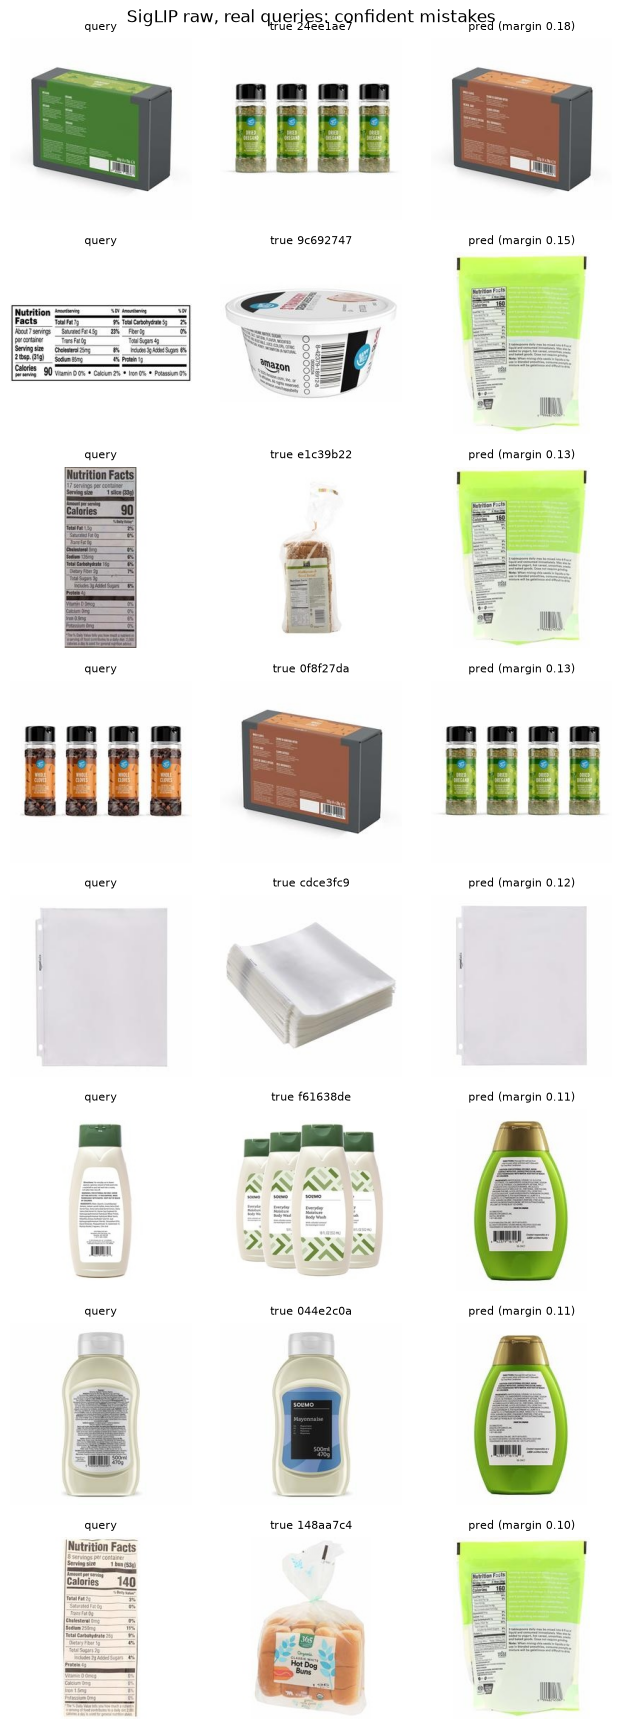

In [13]:
def ref0(p): return Image.open(V / views[(views["product"] == p) & (views.ref_idx == 0)].path.iloc[0])
def grid(df, title, n=8):
    df = df.head(n)
    fig, axes = plt.subplots(len(df), 3, figsize=(6.5, 2.2 * len(df)))
    for r, (_, x) in zip(axes, df.iterrows()):
        q = Image.open(V / views.set_index("view").loc[x.view].path)
        for ax, im, t in zip(r, [q, ref0(x["product"]), ref0(x.pred)],
                             ["query", f"true {x['product'][:10]}", f"pred (margin {x.margin:.2f})"]):
            ax.imshow(im); ax.set_title(t, fontsize=8); ax.axis("off")
    fig.suptitle(title); plt.tight_layout()
d = sel("siglip_b16", "raw")
fails = d[(d.split == "known") & (d.kind == "real") & ~d.correct1].sort_values("margin", ascending=False)
grid(fails, "SigLIP raw, real queries: confident mistakes")

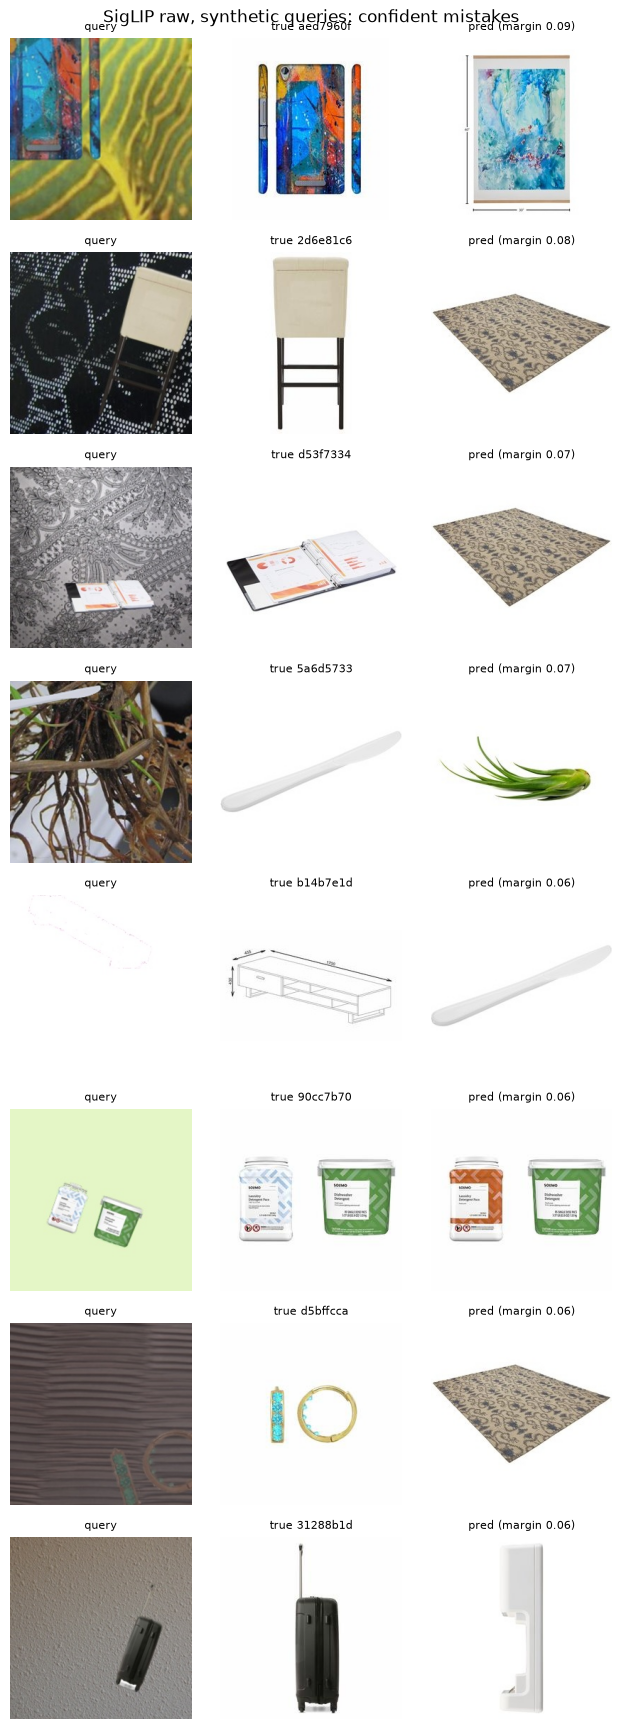

In [14]:
fails = d[(d.split == "known") & (d.kind == "query") & ~d.correct1].sort_values("margin", ascending=False)
grid(fails, "SigLIP raw, synthetic queries: confident mistakes")